# 03 · Strategy and business case

This notebook turns the model into something the bank can run and judge:

1. **Decision rule** — who to sue, how it works month to month, and why each decision was made
2. **Capacity** — what to do if the legal team can only handle a fixed number of cases
3. **Business value** — annual benefit, the logic behind it, assumptions and sensitivities
4. **Pilot design** — a randomised test that proves the rule works, with sample size and the statistical test
5. **Monitoring plan** — what to track, thresholds and actions
6. **Future development and additional data**

All numbers come from the out-of-time test cohorts (2025-07 … 2026-02), which the model never saw during development.

## 0. Setup

In [1]:
import os, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Court-Recovery-Model")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "..")).resolve()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROC_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "reports" / "figures"
MODEL_DIR = PROJECT_DIR / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

FIXED_COST, VAR_COST_RATE = 500, 0.10
PAY_COLS = [f"M{i:02d}_PAID" for i in range(1, 25)]

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def load(name):
    pq = PROC_DIR / f"{name}.parquet"
    return pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / f"{name}.csv")

def gini(y, p):
    from sklearn.metrics import roc_auc_score
    return 2 * roc_auc_score(y, p) - 1

def M(x):
    return f"{x / 1e6:+,.2f}M"

Mounted at /content/drive


In [2]:
bundle = joblib.load(MODEL_DIR / "final_two_part_model.joblib")
FEATURES = bundle["features"]
p_model, r_model = bundle["p_model"], bundle["rate_model"]

data = load("model_dataset")
data = data[data.in_scope == 1].reset_index(drop=True)
data["repaid_share"] = 1 - data.outst / data.principal

scored = load("test_scored")
extra = [c for c in ["net_value_npv", "recovery_npv"] + FEATURES if c not in scored.columns]
scored = scored.merge(data[["CLIENT_KEY", "PERIOD"] + extra], on=["CLIENT_KEY", "PERIOD"], how="left")
scored = scored.sort_values(["PERIOD", "CLIENT_KEY"]).reset_index(drop=True)

N_TEST, N_MONTHS = len(scored), scored.PERIOD.nunique()
SUE = scored.sue.values == 1
print("Final model:", bundle["design"], "| trained on", bundle["trained_on"])
print(f"Test cohorts: {scored.PERIOD.min()} … {scored.PERIOD.max()} | {N_TEST:,} clients over {N_MONTHS} months "
      f"| model sues {SUE.sum():,} ({SUE.mean():.1%})")

Final model: two-part: P=logit, rate=ridge | trained on train+valid (2023-01 … 2025-06)
Test cohorts: 2025/07 … 2026/02 | 6,359 clients over 8 months | model sues 858 (13.5%)


## 1. The decision rule

For each client whose **unsecured** debt reached 120+ DPD and who has **no secured loans** with the bank:

```
P(any payment)       = logistic regression on the client's data at the last month-end before the decision
rate | payment       = ridge regression (share of the debt repaid if the client pays)
expected recovery    = P × rate × outstanding
court cost           = 500 GEL + 10% × outstanding
expected net value   = expected recovery − court cost

→ SUE if expected net value > 0
```

,clients,mean_outstanding,mean_P,mean_rate,mean_expected_net,actual_pay_share,actual_net_per_client
decision,,,,,,,
do not sue,5501,"6,504.735",0.419,0.169,-727.122,0.406,-800.758
sue,858,"13,270.037",0.657,0.349,996.041,0.634,813.603


By balance quintile:


,clients,share_sued,net_if_model,net_if_sue_all
balance_band,,,,
<20%,1272,0.002,400.625,"-642,563.509"
20-40%,1273,0.038,"10,658.103","-653,762.948"
40-60%,1270,0.118,"63,731.201","-668,300.504"
60-80%,1272,0.207,"128,777.820","-767,052.305"
top 20%,1272,0.311,"494,503.669","-975,216.600"


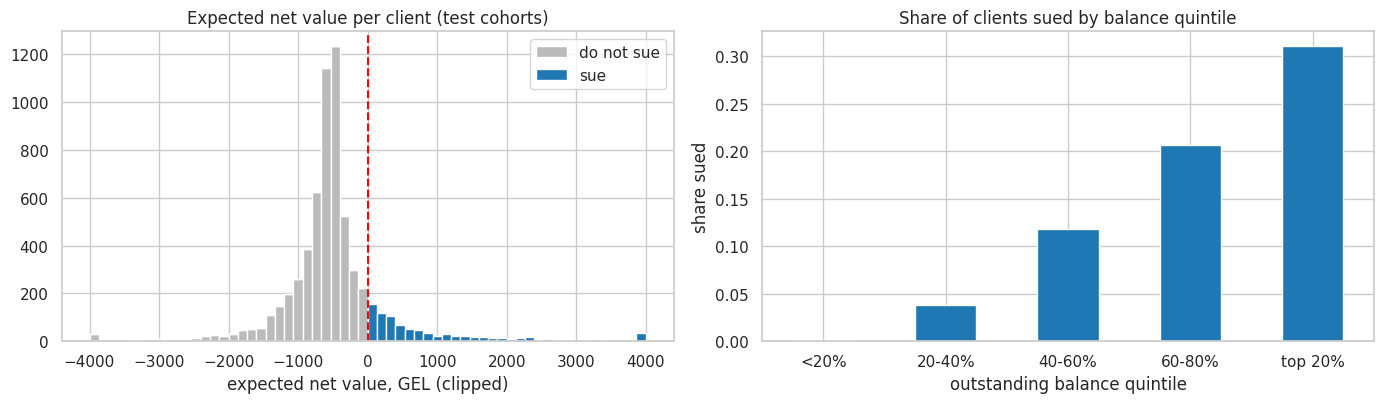

In [3]:
seg = scored.assign(decision=np.where(SUE, "sue", "do not sue"),
                    balance_band=pd.qcut(scored.outst, 5, labels=["<20%", "20-40%", "40-60%", "60-80%", "top 20%"]))
tab = seg.groupby("decision").agg(
    clients=("CLIENT_KEY", "size"), mean_outstanding=("outst", "mean"), mean_P=("p_any_payment", "mean"),
    mean_rate=("rate_given_payment", "mean"), mean_expected_net=("expected_net", "mean"),
    actual_pay_share=("any_payment", "mean"), actual_net_per_client=("net_value_24m", "mean"))
display(tab)

by_band = seg.groupby("balance_band", observed=True).agg(
    clients=("CLIENT_KEY", "size"), share_sued=("sue", "mean"),
    net_if_model=("net_value_24m", lambda s: s[seg.loc[s.index, "sue"] == 1].sum()),
    net_if_sue_all=("net_value_24m", "sum"))
print("By balance quintile:")
display(by_band)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
clip = scored.expected_net.clip(-4000, 4000)
axes[0].hist([clip[~SUE], clip[SUE]], bins=60, stacked=True, label=["do not sue", "sue"], color=["#bbbbbb", "tab:blue"])
axes[0].axvline(0, color="red", ls="--")
axes[0].set(title="Expected net value per client (test cohorts)", xlabel="expected net value, GEL (clipped)")
axes[0].legend()
by_band.share_sued.plot(kind="bar", ax=axes[1], color="tab:blue")
axes[1].set(title="Share of clients sued by balance quintile", xlabel="outstanding balance quintile", ylabel="share sued")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("decision_rule"); plt.show()

The clients the model selects pay far more often and recover far more than the ones it rejects, and the rule
concentrates on larger balances, where recovery can cover the 500 GEL fixed fee. Small debts are almost never sued.

### Reason codes: why each client was or was not selected

Because P(any payment) is a logistic regression, each client's score splits exactly into feature contributions
(standardised value × coefficient). The strongest contributions become **reason codes** that the collections team
can read for every decision, which matters for audit, model governance and expert overrides.

In [4]:
prep, logit = p_model.named_steps["prep"], p_model.named_steps["model"]
names = [c for _, _, cols in prep.transformers_ if cols != "drop" for c in cols]
Z = prep.transform(scored[FEATURES])
contrib = pd.DataFrame(Z * logit.coef_[0], columns=names, index=scored.index)

SHORT = {"feature_003": "credit turnover", "feature_006": "share of cash withdrawals", "feature_011": "deposit balance",
         "feature_012": "max account balance", "feature_013": "days with zero balance", "feature_014": "payroll inflow",
         "feature_016": "card limit utilisation", "feature_017": "loans closed without delinquency",
         "feature_018": "other active loans", "feature_019": "share of instalments paid late",
         "feature_020": "revolving utilisation", "feature_021": "times 30+ days past due", "feature_022": "restructurings",
         "feature_023": "share of instalment paid", "feature_026": "months with app activity", "feature_031": "bureau score",
         "feature_034": "behavioural score", "feature_036": "overdue share of bureau debt", "feature_039": "declared income",
         "feature_041": "instalments / inflow", "feature_043": "recent credit applications", "outst": "outstanding balance",
         "principal": "original principal", "n_loans": "number of loans", "repaid_share": "share repaid before default"}
FLAGS = {"feature_011_missing": ("no deposit product", "has a deposit product"),
         "feature_039_missing": ("no declared income", "has declared income")}
fdict = pd.read_csv(RAW_DIR / "feature_dictionary.csv").set_index("column")

def label(c, z):
    """Readable reason: the feature name plus whether the client's value is high or low."""
    if c in FLAGS:
        return FLAGS[c][0] if z > 0 else FLAGS[c][1]
    name = SHORT.get(c, " ".join(fdict.description.get(c, c).split()[:5]).lower())
    return f"{'high' if z > 0 else 'low'} {name}"

Zdf = pd.DataFrame(Z, columns=names, index=scored.index)

def reasons(i, k=3):
    row = contrib.loc[i]
    top = row.sort_values(ascending=not SUE[i]).head(k)
    return [label(c, Zdf.loc[i, c]) for c in top.index]

scored["reasons"] = [reasons(i) for i in scored.index]

examples = list(scored.index[SUE][:2]) + list(scored.index[~SUE][:2])
display(pd.DataFrame({
    "decision": np.where(SUE[examples], "SUE", "do not sue"),
    "P(any payment)": scored.loc[examples, "p_any_payment"].round(2).values,
    "expected net (GEL)": scored.loc[examples, "expected_net"].round(0).values,
    "main reasons": ["; ".join(scored.loc[i, "reasons"]) for i in examples]},
    index=[f"example {k + 1}" for k in range(len(examples))]))

top_reason = scored.reasons.str[0]
common = pd.concat({"most common main reason — SUE": top_reason[SUE].value_counts(normalize=True).head(6),
                    "most common main reason — DO NOT SUE": top_reason[~SUE].value_counts(normalize=True).head(6)}, axis=1)
display(common.style.format("{:.1%}", na_rep=""))

,decision,P(any payment),expected net (GEL),main reasons
example 1,SUE,0.580,"1,072.000",high max account balance; low share of instalm...
example 2,SUE,0.560,649.000,low overdue share of bureau debt; has declared...
example 3,do not sue,0.530,-402.000,high share of cash withdrawals; high recent cr...
example 4,do not sue,0.590,-51.000,high share of instalments paid late; low other...


,most common main reason — SUE,most common main reason — DO NOT SUE
reasons,,
high bureau score,23.4%,
has a deposit product,22.7%,
high max account balance,17.1%,
low share of instalments paid late,13.2%,
high credit turnover,10.4%,
low overdue share of bureau debt,4.1%,
no declared income,,26.2%
low bureau score,,14.7%
low max account balance,,11.4%


## 2. When legal capacity is limited

If the legal team can only open N new cases per month, the rule becomes: **rank clients by expected net value and
sue the top N (only those with expected net > 0)**. Ranking by expected *money* rather than probability matters:
a client with a high chance of paying but a tiny balance cannot cover the fixed fee.

Unconstrained rule sues 107 clients per month on average (range 98–122)


,cases_total,net_value,net_per_case,net_value_if_ranked_by_P
cases_per_month,,,,
10,80,"323,342.818","4,041.785","226,219.468"
25,200,"562,002.587","2,810.013","402,456.611"
50,400,"665,877.340","1,664.693","546,977.069"
75,600,"659,217.320","1,098.696","676,446.690"
100,797,"704,433.994",883.857,"756,952.255"
125,858,"698,071.418",813.603,"698,071.418"
150,858,"698,071.418",813.603,"698,071.418"


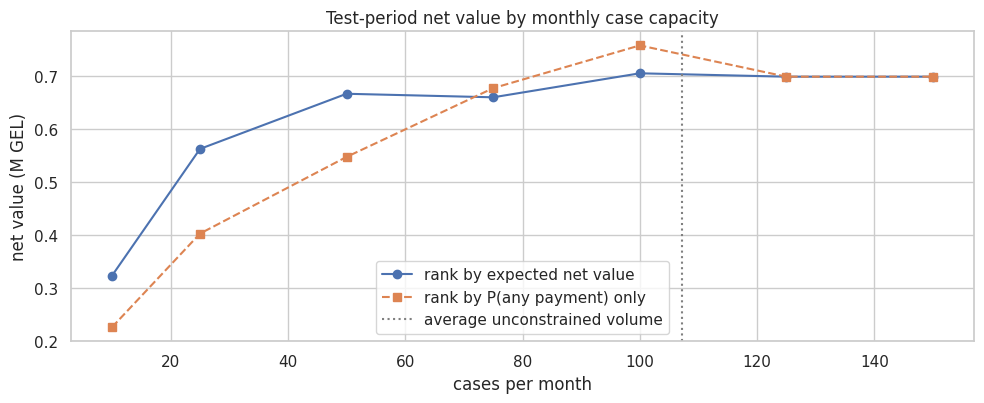

In [5]:
def capacity_value(df, cap, score="expected_net"):
    value, cases = 0.0, 0
    for _, g in df.groupby("PERIOD"):
        g = g[g.expected_net > 0].sort_values(score, ascending=False).head(cap)
        value += g.net_value_24m.sum(); cases += len(g)
    return cases, value

scored["roi"] = scored.expected_net / scored.court_cost
caps = [10, 25, 50, 75, 100, 125, 150]
rows = []
for cap in caps:
    c, v = capacity_value(scored, cap)
    c_p, v_p = capacity_value(scored, cap, score="p_any_payment")
    rows.append({"cases_per_month": cap, "cases_total": c, "net_value": v, "net_per_case": v / max(c, 1),
                 "net_value_if_ranked_by_P": v_p})
cap_tab = pd.DataFrame(rows).set_index("cases_per_month")
unconstrained = scored.groupby("PERIOD").sue.sum()
print(f"Unconstrained rule sues {unconstrained.mean():.0f} clients per month on average "
      f"(range {unconstrained.min()}–{unconstrained.max()})")
display(cap_tab)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(cap_tab.index, cap_tab.net_value / 1e6, marker="o", label="rank by expected net value")
ax.plot(cap_tab.index, cap_tab.net_value_if_ranked_by_P / 1e6, marker="s", ls="--", label="rank by P(any payment) only")
ax.axvline(unconstrained.mean(), color="grey", ls=":", label="average unconstrained volume")
ax.set(title="Test-period net value by monthly case capacity", xlabel="cases per month", ylabel="net value (M GEL)")
ax.legend(); plt.tight_layout(); savefig("capacity_value"); plt.show()

## 3. Business value

**Logic.** The historical data contains only clients the experts sent to court, so **"sue everyone" = current practice**.
The model changes the decision only for clients it rejects:

```
benefit vs current practice = court costs avoided on rejected clients − recovery given up on rejected clients
```

The benefit per client is measured on the test cohorts and scaled to a year of volume.

In [6]:
rej = ~SUE
costs_avoided = scored.court_cost[rej].sum()
recovery_forgone = scored.recovery_24m[rej].sum()
benefit = costs_avoided - recovery_forgone
sue_all = scored.net_value_24m.sum()
model_net = scored.net_value_24m[SUE].sum()

annual_volume = (data.PERIOD.str[:4] == "2025").sum()
scale = annual_volume / N_TEST

bridge = pd.Series({
    "Net result, sue everyone (current practice)": sue_all,
    "+ court costs avoided on rejected clients": costs_avoided,
    "− recovery given up on rejected clients": -recovery_forgone,
    "= Net result with the model": model_net,
    "Benefit vs current practice": benefit,
    "Benefit vs suing no one": model_net}, name="test period, GEL").to_frame()
bridge["per client"] = bridge.iloc[:, 0] / N_TEST
bridge["annualised"] = bridge.iloc[:, 0] * scale
display(bridge)
print(f"Annual volume: {annual_volume:,} in-scope clients (calendar 2025); test period: {N_TEST:,} clients in {N_MONTHS} months")

,"test period, GEL",per client,annualised
"Net result, sue everyone (current practice)","-3,706,895.867",-582.937,"-5,215,536.613"
+ court costs avoided on rejected clients,"6,328,754.589",995.244,"8,904,445.244"
− recovery given up on rejected clients,"-1,923,787.305",-302.530,"-2,706,734.552"
= Net result with the model,"698,071.418",109.777,"982,174.080"
Benefit vs current practice,"4,404,967.284",692.714,"6,197,710.692"
Benefit vs suing no one,"698,071.418",109.777,"982,174.080"


Annual volume: 8,947 in-scope clients (calendar 2025); test period: 6,359 clients in 8 months


In [7]:
gain = np.where(SUE, 0.0, -scored.net_value_24m.values)
boot = np.array([gain[rng.integers(0, N_TEST, N_TEST)].mean() for _ in range(5000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Benefit per client: {gain.mean():,.0f} GEL (95% CI {lo:,.0f} … {hi:,.0f})")
print(f"Annual benefit vs current practice: {gain.mean() * annual_volume / 1e6:,.2f}M GEL "
      f"(95% CI {lo * annual_volume / 1e6:,.2f}M … {hi * annual_volume / 1e6:,.2f}M)")

Benefit per client: 693 GEL (95% CI 660 … 724)
Annual benefit vs current practice: 6.20M GEL (95% CI 5.91M … 6.48M)


## 4. Pilot design

### Goal and hypotheses
Prove, with a randomised experiment, that the model rule produces more net money per client than the current expert
practice, and measure the two things historical data cannot show: **what unsued clients pay on their own** and
**what is lost on clients the model rejects**.

- **H0:** mean net value per client (model rule) − mean net value per client (current practice) ≤ 0
- **H1:** the difference is > 0
- Significance α = 5% (two-sided test, reported with a 95% confidence interval), power 80%

### Design
- **Unit:** client (one court decision covers all of a client's loans).
- **Population:** every client reaching the court decision with unsecured debt only — the population the model is meant for.
- **Randomisation:** each month, eligible clients are scored first, then randomly assigned **within strata**
  (expected-net decile × balance band) so both arms have the same mix of risk and size:
  - **Control arm:** the current expert process decides.
  - **Model arm:** the model rule decides (expert overrides allowed and logged).
- **Exploration slice:** inside the model arm, a random **10% of model-rejected clients are sued anyway**.
  This measures the recovery the model gives up and keeps future training data free of the model's own selection bias.
- **Primary metric:** net value per client = recovery − court cost (0 cost if not sued), measured at 24 months,
  with an **early readout at 6 months** using the development factor (24-month value ≈ 6-month recovery × 2.44).
- **Secondary metrics:** cases opened, court costs, recovery rate, share of sued clients who pay anything,
  **voluntary payments of unsued clients** (the counterfactual), override rate.
- **Statistical test:** Welch's t-test on the mean net value per client, confirmed with a bootstrap 95% CI for the difference.
  Regression adjustment on the pre-assignment expected net value (known before randomisation) reduces variance.
  The Mann-Whitney test is not used as the primary test because it compares ranks, not money: the bank cares about the **mean** GEL per client.

### Sample size
Variances and the expected effect are taken from the test cohorts, where "current practice" = sue everyone.
Because the true effect may be smaller than the backtest suggests, the pilot is sized to detect **25% of the estimated effect**.

In [9]:
rec = pd.read_csv(RAW_DIR / "loan_month_recovery.csv")
keys = ["CLIENT_KEY", "PERIOD"]
in_scope_keys = rec.groupby(keys).HAS_COLLATERAL.max().eq(0)
rec = rec.set_index(keys).loc[in_scope_keys[in_scope_keys].index].reset_index()
cl = rec.groupby(keys).agg(months_obs=("MONTHS_OBSERVED", "max"), **{c: (c, "sum") for c in PAY_COLS[:6]})
full_m = rec[rec.MONTHS_OBSERVED == 24]
F6 = full_m[PAY_COLS].sum().sum() / full_m[PAY_COLS[:6]].sum().sum()
print(f"Development factor 6 → 24 months: {F6:.3f}")

cl["paid_6m"] = cl[PAY_COLS[:6]].sum(axis=1)
scored = scored.merge(cl[["paid_6m"]].reset_index(), on=keys, how="left")
scored["net_6m_readout"] = np.minimum(scored.paid_6m * F6, scored.outst) - scored.court_cost
print(f"Correlation of 6-month readout with the 24-month value: "
      f"{np.corrcoef(scored.net_6m_readout, scored.net_value_24m)[0, 1]:.3f}")

Development factor 6 → 24 months: 2.425
Correlation of 6-month readout with the 24-month value: 0.991


In [10]:
explore = (~SUE) & (rng.random(N_TEST) < 0.10)
sue_model_arm = SUE | explore
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)

def required_n(metric, frac, share_model=0.5, adjust=False):
    a = scored[metric].values
    b = np.where(sue_model_arm, a, 0.0)
    va, vb = a.var(), b.var()
    if adjust:
        x = scored.expected_net.values
        va *= 1 - np.corrcoef(a, x)[0, 1] ** 2
        vb *= 1 - np.corrcoef(b, x)[0, 1] ** 2
    delta = (b.mean() - a.mean()) * frac
    n_total = z ** 2 * (va / (1 - share_model) + vb / share_model) / delta ** 2
    return delta, int(np.ceil(n_total))

monthly = annual_volume / 12
rows = []
for metric, label in [("net_value_24m", "24-month value"), ("net_6m_readout", "6-month readout")]:
    for frac in (1.0, 0.5, 0.25):
        for adj in (False, True):
            delta, n = required_n(metric, frac, adjust=adj)
            rows.append({"metric": label, "effect to detect": f"{frac:.0%} of estimate", "regression adjusted": adj,
                         "effect, GEL/client": delta, "total clients needed": n, "months of intake": n / monthly})
power_tab = pd.DataFrame(rows)
display(power_tab)
print(f"Monthly in-scope volume ≈ {monthly:,.0f} clients")

,metric,effect to detect,regression adjusted,"effect, GEL/client",total clients needed,months of intake
0,24-month value,100% of estimate,False,618.854,309,0.414
1,24-month value,100% of estimate,True,618.854,265,0.355
2,24-month value,50% of estimate,False,309.427,1236,1.658
3,24-month value,50% of estimate,True,309.427,1057,1.418
4,24-month value,25% of estimate,False,154.713,4944,6.631
5,24-month value,25% of estimate,True,154.713,4225,5.667
6,6-month readout,100% of estimate,False,621.329,300,0.402
7,6-month readout,100% of estimate,True,621.329,257,0.345
8,6-month readout,50% of estimate,False,310.665,1199,1.608
9,6-month readout,50% of estimate,True,310.665,1026,1.376


Monthly in-scope volume ≈ 746 clients


In [11]:
def simulate_power(n_per_arm, frac, reps=1000):
    a = scored.net_value_24m.values
    b = a + frac * (np.where(sue_model_arm, a, 0.0) - a)
    hits = 0
    for _ in range(reps):
        xa, xb = rng.choice(a, n_per_arm), rng.choice(b, n_per_arm)
        t = stats.ttest_ind(xb, xa, equal_var=False)
        hits += (t.pvalue < 0.05) and (xb.mean() > xa.mean())
    return hits / reps

sim = pd.DataFrame([{"clients per arm": n, "effect": f"{f:.0%} of estimate", "simulated power": simulate_power(n, f)}
                    for n in (250, 1000, 2000, 2500) for f in (1.0, 0.25)])
display(sim.pivot(index="clients per arm", columns="effect", values="simulated power"))

effect,100% of estimate,25% of estimate
clients per arm,,
250,0.918,0.141
1000,1.000,0.396
2000,1.000,0.675
2500,1.000,0.750


In [12]:
gain_per_client = (np.where(sue_model_arm, scored.net_value_24m, 0) - scored.net_value_24m).mean()
alloc = []
for share in (0.5, 0.7, 0.8):
    _, n = required_n("net_value_24m", 0.25, share_model=share, adjust=True)
    n_control = n * (1 - share)
    alloc.append({"model : control": f"{share:.0%} : {1 - share:.0%}", "total clients": n,
                  "months of intake": n / monthly, "control clients": int(n_control),
                  "expected cost of the control arm (GEL)": n_control * gain_per_client})
display(pd.DataFrame(alloc).set_index("model : control"))

_, n_rec = required_n("net_6m_readout", 0.25, share_model=0.7, adjust=True)
months_rec = int(np.ceil(n_rec / monthly))
print(f"Recommended pilot: 70:30 split, {n_rec:,} clients ≈ {months_rec} months of intake "
      f"(~{int(n_rec * 0.7):,} model arm / ~{int(n_rec * 0.3):,} control), main readout 6 months after the last intake "
      f"→ month {months_rec + 6}")

,total clients,months of intake,control clients,expected cost of the control arm (GEL)
model : control,,,,
50% : 50%,4225,5.667,2112,"1,307,328.170"
70% : 30%,5350,7.176,1605,"993,259.982"
80% : 20%,7231,9.698,1446,"894,986.035"


Recommended pilot: 70:30 split, 5,196 clients ≈ 7 months of intake (~3,637 model arm / ~1,558 control), main readout 6 months after the last intake → month 13


## 5. Monitoring plan

The model is used every month, while its outcomes mature over 24 months. Monitoring therefore combines **input checks**
(available immediately), **early outcome checks** (from month 1–6, using the fact that payers start paying in month 1)
and **full outcome checks** (12–24 months).

In [13]:
def psi(ref, cur, bins=10):
    ref, cur = np.asarray(ref), np.asarray(cur)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

dev = data[data.split.isin(["train", "valid"])]
ref_p = p_model.predict_proba(dev[FEATURES])[:, 1]
ref_share_sued = ((ref_p * np.clip(r_model.predict(dev[FEATURES]), 0, 1) * dev.outst - dev.court_cost) > 0).mean()

report = scored.groupby("PERIOD").apply(lambda g: pd.Series({
    "clients": len(g),
    "share sued": g.sue.mean(),
    "PSI of P(any payment)": psi(ref_p, g.p_any_payment),
    "PSI feature_007": psi(dev.feature_007.dropna(), g.feature_007.dropna()),
    "early pay rate: predicted": g.p_any_payment.mean(),
    "early pay rate: actual": g.any_payment.mean(),
    "recovery: predicted / actual": (g.p_any_payment * g.rate_given_payment * g.outst).sum() / g.recovery_24m.sum(),
    "Gini P(any payment)": gini(g.any_payment, g.p_any_payment)})).T
print(f"Reference share sued (development period): {ref_share_sued:.1%}")
display(report)

Reference share sued (development period): 14.6%


PERIOD,2025/07,2025/08,2025/09,2025/10,2025/11,2025/12,2026/01,2026/02
clients,764.000,765.000,791.000,757.000,823.000,786.000,832.000,841.000
share sued,0.136,0.144,0.144,0.141,0.126,0.126,0.118,0.145
PSI of P(any payment),0.008,0.005,0.007,0.010,0.012,0.014,0.014,0.017
PSI feature_007,0.060,0.039,0.092,0.127,0.085,0.118,0.063,0.111
early pay rate: predicted,0.449,0.450,0.457,0.449,0.453,0.446,0.446,0.457
early pay rate: actual,0.432,0.418,0.449,0.417,0.433,0.461,0.453,0.433
recovery: predicted / actual,0.998,1.354,1.275,1.317,1.109,0.941,1.142,1.086
Gini P(any payment),0.343,0.246,0.297,0.245,0.316,0.286,0.215,0.296


## 6. Future development

1. **Recalibrate on the newest cohorts** and re-estimate the development factors as more 2025 cohorts mature.
2. **Use the pilot data** to estimate the *incremental* effect of court (court recovery minus voluntary payment),
   then move from "predict recovery" to an **uplift model**: sue the clients for whom court changes the outcome most.
3. **Model the timing of payments** (survival or monthly cash-flow model) to optimise on NPV directly and to read
   pilot results earlier.
4. **Combine with pre-court collection strategies**: for rejected clients, test cheaper actions (restructuring offers,
   reminders, settlement discounts) instead of doing nothing.
5. **Revisit gradient boosting** once richer data (below) adds interactions the current features do not capture,
   with proper early stopping and regularisation tuning.
6. **Capacity-aware optimisation**: if legal capacity or regional courts become binding, optimise the case mix across
   months and regions.

## 7. Additional data that would help

| Data | Why it would help |
|---|---|
| Outcomes of clients **not** sent to court (voluntary payments, write-offs) | Measures the counterfactual and removes the selection bias; enables uplift modelling |
| Property, vehicle and land registry records | Assets the court can enforce against are the strongest predictor of court recovery |
| Employment and salary data (e.g. pension / social-security contributions, employer) | Salary garnishment is a main enforcement channel |
| Court and enforcement details: region, court, enforcement bureau, time to judgment, actual legal costs | Real costs and regional enforcement speed instead of the flat 500 GEL + 10% assumption |
| Pre-court collection history: calls, promises to pay, broken promises, contact rate | Strong behavioural signal of willingness to pay |
| Debts at other banks and new credit after default (full bureau data) | Shows financial capacity and competing creditors |
| Demographics and contact information quality (age, region, reachable phone/address) | Unreachable clients rarely pay, even after a judgment |
| Income verification and transaction categories after default | Ongoing capacity to pay rather than a snapshot before default |

## 8. Summary

- **Rule:** sue an unsecured client when P(any payment) × rate × outstanding exceeds 500 GEL + 10% of outstanding;
  every decision comes with reason codes. With limited capacity, rank by expected net value and take the top N.
- **Value:** on the newest unseen cohorts the rule sues about 1 in 7 clients and turns a 3.7M GEL loss into a 0.7M GEL profit.
  Annualised on 2025 volume: **+6.2M GEL per year vs current practice** (95% CI 5.9M … 6.5M), of which **+1.0M** is profit
  from the cases themselves; the rest is court costs no longer wasted on clients who would not pay.
  The benefit vs current practice stays positive in every sensitivity tested.
- **Pilot:** stratified randomised trial, 70:30 model vs current practice, Welch t-test with regression adjustment,
  sized to detect 25% of the estimated effect (~5,200 clients, ~7 months of intake); main readout 6 months after the
  last intake, confirmed at 12 and 24 months.
  It also measures voluntary payments and the cost of rejected clients.
- **Monitoring:** data checks every run; monthly drift and early calibration (pay rate after 1 month); quarterly recovery
  calibration, Gini and business result; annual retrain; permanent exploration slice against selection bias.